# STAT GR5398 Fall 2026 Assignment 1 - FinRL-Trading
JIAO XU / jx2687

## Results at a glance
Executed purged quarterly strategy, 2020-06-30 to 2025-09-30. Net cumulative return **109.10%**, SPY **132.66%**, QQQ **150.00%**. Strategy underperformed SPY. Missing historical prices prevent a full survivorship-free-universe claim. This notebook is an executed result-validation companion; `run_analysis.py` is the deterministic full model/backtest reproducer. Original 104-minute training is preserved in `cache/`, not rerun. See Research_Report.pdf for methodology and material limitations.

## Context and methods
Use PIT members at each quarterly cutoff, completed labels only, conservative feature availability, fixed RF/ET models, top 25%, equal target weights, next trading close execution, share holdings between quarterly rebalances, 0.1% gross traded-notional costs. Unavailable entry targets stay in cash; missing held quotes stop valuation. Historical provider coverage and restatement/corporate-action metadata remain unresolved. Original cached signal returns are not an unbiased baseline.

### Reproduce the model fit
From this folder, run the exact commands in README.md. `python run_analysis.py --source /path/to/source_code --output rerun_results --benchmark-dir benchmark_data` refits only the new fixed experiment (roughly one minute locally). Do not rerun the old entire notebook.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / "results/metrics.csv").is_file(), "Run this notebook from the submission folder"
summary = json.loads((ROOT / "results/audit_summary.json").read_text())
metrics = pd.read_csv(ROOT / "results/metrics.csv")
nav = pd.read_csv(ROOT / "results/comparison_nav.csv", index_col=0, parse_dates=True)
strategy = pd.read_csv(ROOT / "results/strategy_daily.csv", index_col=0, parse_dates=True)
display(metrics.round(6))

,strategy,start,end,days,final_nav,cumulative_return,cagr,volatility,sharpe,max_drawdown,mean_turnover,total_cost_sum
0,Purged ML,2020-06-30,2025-09-30,1319,2.090961,1.090961,0.150812,0.159758,0.962173,-0.222241,0.010297,0.013599
1,SPY,2020-06-30,2025-09-30,1319,2.326650,1.326650,0.174458,0.172391,1.022134,-0.244964,0.000000,0.000000
2,QQQ,2020-06-30,2025-09-30,1319,2.499955,1.499955,0.190637,0.230293,0.875352,-0.351187,0.000000,0.000000


## Data and missing-price coverage

In [2]:
print({k: summary[k] for k in ["prepared_rows", "prepared_tickers", "quarters", "pit_removed_rows", "pit_removed_tickers", "original_rows", "original_tickers", "new_target_records", "new_missing_targets"]})
missing = pd.read_csv(ROOT / "results/missing_price_tickers.csv")
assert len(missing) == 62
print("Completely missing original tickers:", len(missing), "Original affected records:", missing.selected_records.sum())
display(missing.sort_values("selected_records", ascending=False).head(10))

{'prepared_rows': 19007, 'prepared_tickers': 674, 'quarters': 42, 'pit_removed_rows': 2292, 'pit_removed_tickers': 18, 'original_rows': 174571, 'original_tickers': 418, 'new_target_records': 2622, 'new_missing_targets': 282}
Completely missing original tickers: 62 Original affected records: 18300


,tic,selected_records
32,JNPR,1280
18,ENPH,1156
4,ANSS,912
25,FMC,865
45,QRVO,805
11,CE,797
6,ATVI,744
47,RHI,714
0,AAL,645
21,FISV,629


## Verify information timing and portfolio accounting

In [3]:
timing = pd.read_csv(ROOT / "results/timing_and_rebalance_audit.csv")
for field in ["train_label_end", "validation_label_end"]:
    assert (pd.to_datetime(timing[field]) <= pd.to_datetime(timing.cutoff)).all()
assert (pd.to_datetime(timing.execution) > pd.to_datetime(timing.cutoff)).all()
selected = pd.read_csv(ROOT / "results/purged_selected.csv")
assert (pd.to_datetime(selected.available) <= pd.to_datetime(selected.cutoff)).all()
assert not selected.duplicated(["cutoff", "ticker"]).any()
weights = pd.read_csv(ROOT / "results/target_weights.csv", index_col=0)
assert weights.ge(0).all().all() and (weights.sum(axis=1) <= 1 + 1e-10).all()
assert np.isfinite(strategy[["nav", "net_ret"]].to_numpy()).all()
assert np.allclose(strategy.nav, (1 + strategy.net_ret).cumprod(), rtol=1e-10)
assert np.allclose(strategy.net_ret, strategy.gross_ret - strategy.cost, atol=1e-12)
assert (strategy.turnover >= 0).all() and (strategy.cost >= 0).all()
print("PASS: information timing, unique selections, nonnegative weights, NAV and costs")
display(timing.head())

PASS: information timing, unique selections, nonnegative weights, NAV and costs


,cutoff,execution,train_rows,validation_rows,train_label_end,validation_label_end,model,universe,selected,unexecuted_weight
0,2020-06-30,2020-07-01,5710,1949,2019-09-03,2020-06-01,RF,492,123,0.097561
1,2020-09-30,2020-10-01,6196,1961,2019-09-03,2020-09-01,RF,498,125,0.160000
2,2020-12-31,2021-01-04,6627,1966,2020-03-02,2020-12-01,RF,498,125,0.200000
3,2021-03-31,2021-04-01,7055,1970,2020-06-01,2021-03-01,RF,495,124,0.233871
4,2021-06-30,2021-07-01,7492,1947,2020-09-01,2021-06-01,ET,497,125,0.200000


## Independently recompute reported performance

In [4]:
checks = []
years = (nav.index[-1] - nav.index[0]).days / 365.25
for name in nav:
    returns = nav[name].pct_change(fill_method=None).dropna()
    computed = {"cumulative_return": nav[name].iloc[-1] - 1,
                "cagr": nav[name].iloc[-1] ** (1/years) - 1,
                "volatility": returns.std(ddof=1) * np.sqrt(252),
                "sharpe": returns.mean() / returns.std(ddof=1) * np.sqrt(252),
                "max_drawdown": (nav[name] / nav[name].cummax() - 1).min()}
    saved = metrics.set_index("strategy").loc[name]
    for key,value in computed.items():
        assert np.isclose(value, saved[key], atol=1e-10), (name,key)
    checks.append({"strategy": name, **computed})
assert nav.index.is_unique and nav.notna().all().all()
assert (nav.iloc[0] == 1).all()
assert nav.index[0] == pd.Timestamp("2020-06-30")
assert nav.index[-1] == pd.Timestamp("2025-09-30")
print("PASS: all five performance measures for every series independently recomputed")
display(pd.DataFrame(checks))

PASS: all five performance measures for every series independently recomputed


,strategy,cumulative_return,cagr,volatility,sharpe,max_drawdown
0,Purged ML,1.090961,0.150812,0.159758,0.962173,-0.222241
1,SPY,1.326650,0.174458,0.172391,1.022134,-0.244964
2,QQQ,1.499955,0.190637,0.230293,0.875352,-0.351187


## Charts and model evidence

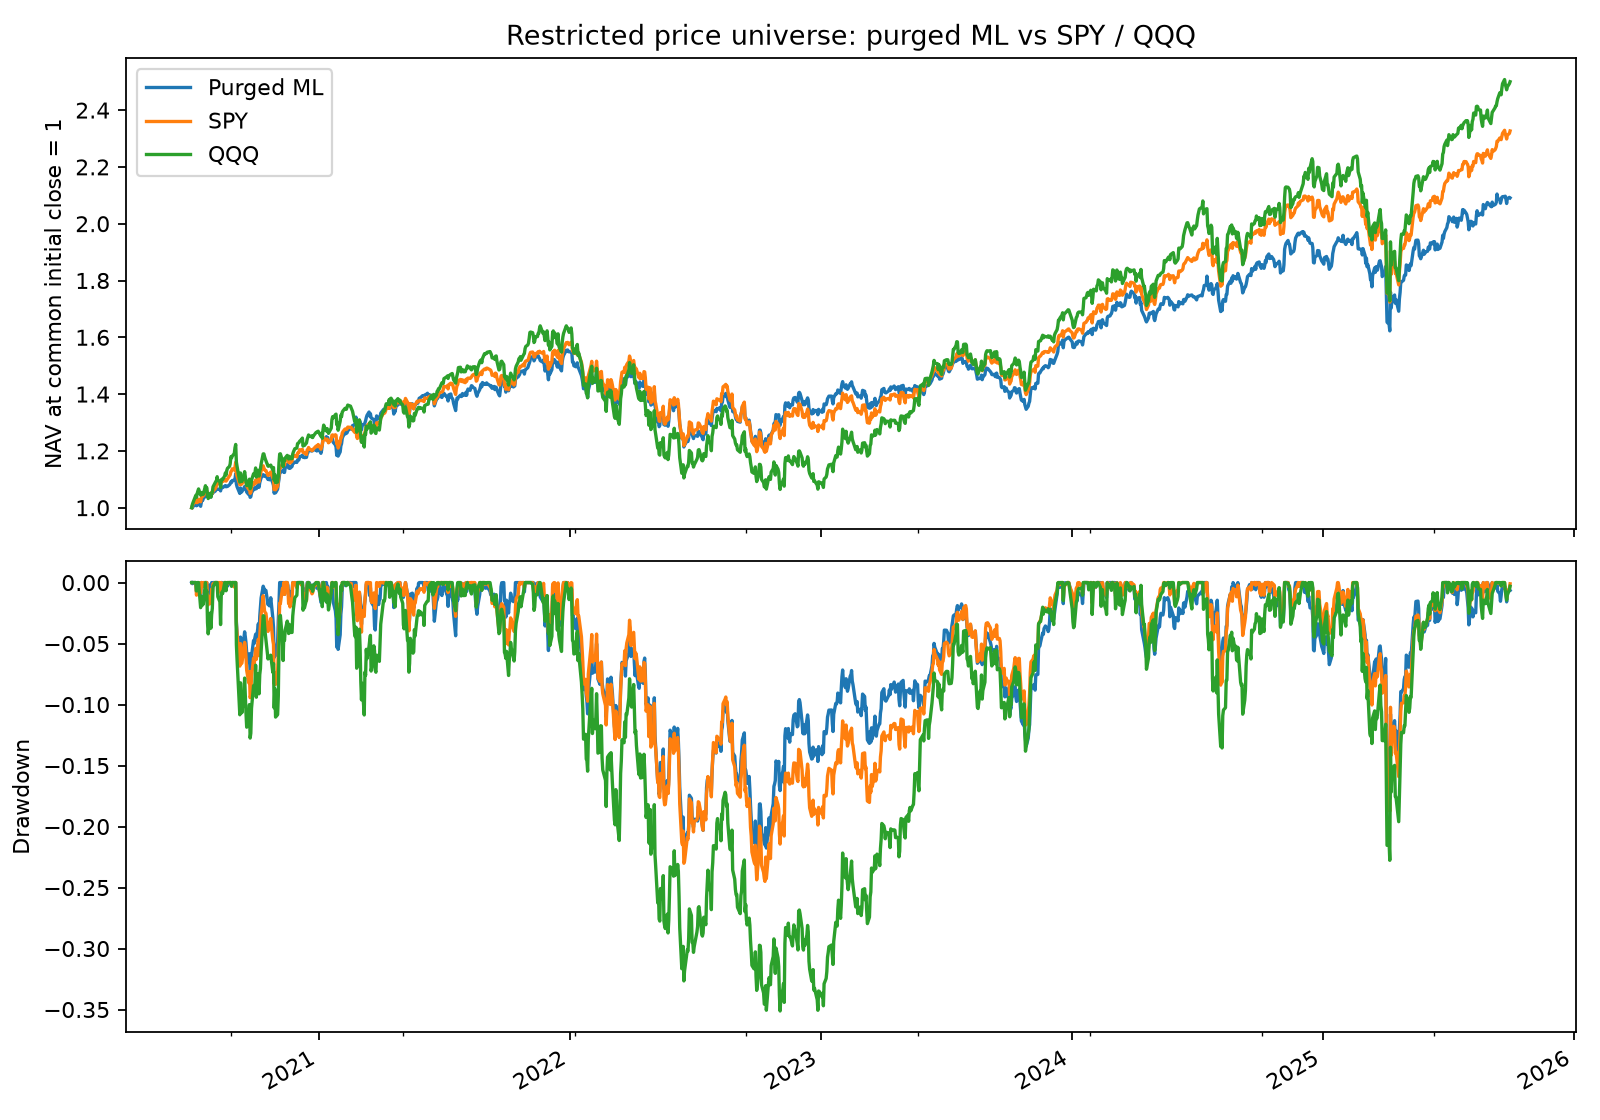

Original winner counts: {'xgb': 88, 'gbm': 63, 'rf': 87}
Purged replacement winner counts: {'ET': 15, 'RF': 6}


,feature,importance
0,asset_turnover,0.094689
1,revenue_per_share,0.080629
2,BPS,0.079392
3,debt_to_capital,0.053555
4,cash_ratio,0.050529
5,debt_ratio,0.047630
6,debt_to_assets,0.046799
7,lt_debt_to_capital,0.044987
8,cash_per_share,0.044137
9,gross_margin,0.043317


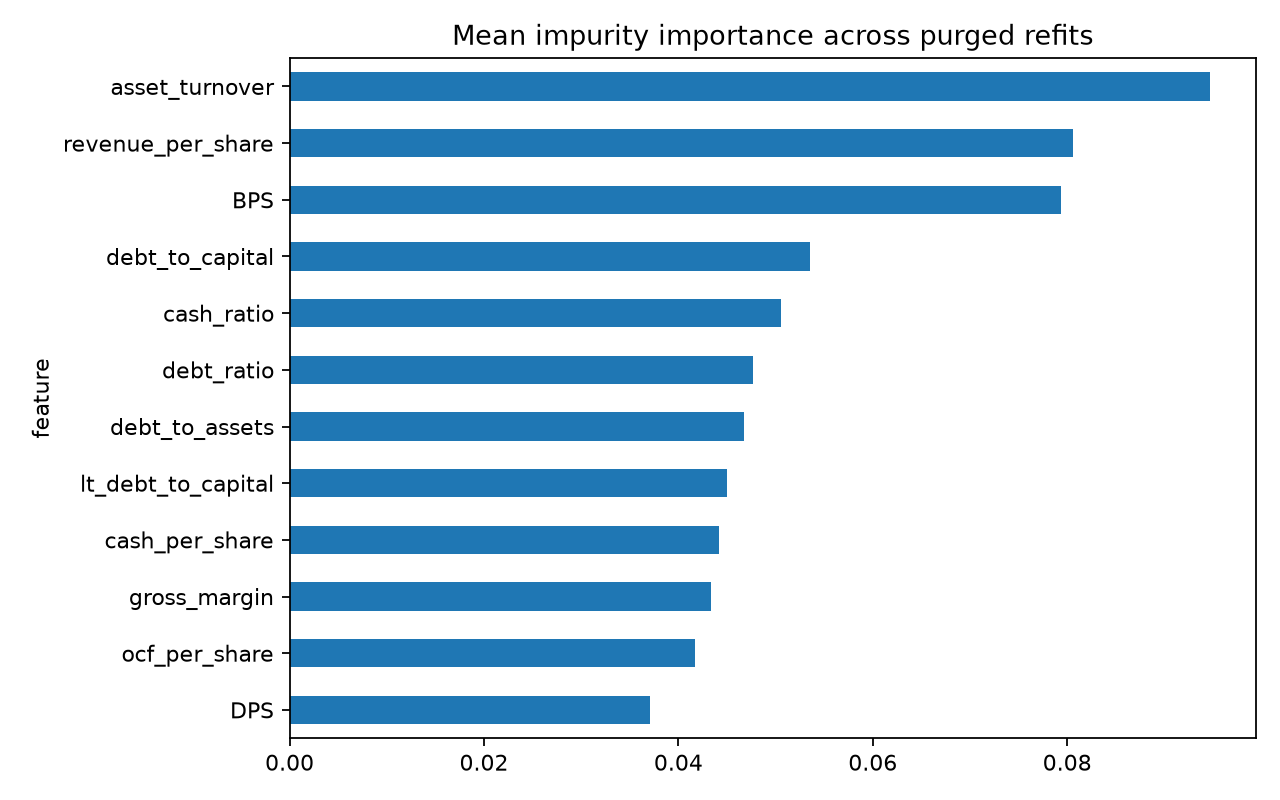

In [5]:
display(Image(filename=str(ROOT / "results/comparison.png")))
print("Original winner counts:", summary["original_winners"])
print("Purged replacement winner counts:", summary["new_winners"])
display(pd.read_csv(ROOT / "results/feature_importance.csv").head(10))
display(Image(filename=str(ROOT / "results/feature_importance.png")))

## Interpretation and incomplete requirements
The strategy did not beat SPY. The cash allocation and restricted historical price coverage affect both risk and returns. PIT filtering is implemented, but full price-universe survivorship freedom is not established; provider restatements and corporate actions remain unverified. Feature importance is replacement-model impurity importance, not original-model or causal importance. The quoted-only original baseline diagnostic is invalid for full performance conclusions.

Submission remaining: review this analysis and the AI-assistance disclosure; publish/adapt Medium_draft.md and add its link in README.md; manually place Assignment1_JIAOXU_jx2687 under the course track submissions directory and open the PR. No external submission, publication or live trading was performed. Exact deadline hour/timezone remain unconfirmed. See requirements_checklist.md.